# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [141]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [142]:
df = pd.read_csv("data/AviationData_cleaned.csv")

C:\Users\USER\AppData\Local\Temp\ipykernel_29016\1702097378.py:1: DtypeWarning: Columns (27: Broad.phase.of.flight) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/AviationData_cleaned.csv")


In [143]:
df.shape

(19937, 47)

In [144]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19937 entries, 0 to 19936
Data columns (total 47 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Event.Id                           19937 non-null  str    
 1   Investigation.Type                 19937 non-null  str    
 2   Accident.Number                    19937 non-null  str    
 3   Event.Date                         19937 non-null  str    
 4   Location                           19934 non-null  str    
 5   Country                            19935 non-null  str    
 6   Latitude                           18574 non-null  str    
 7   Longitude                          18568 non-null  str    
 8   Airport.Code                       13364 non-null  str    
 9   Airport.Name                       13423 non-null  str    
 10  Injury.Severity                    19712 non-null  str    
 11  Aircraft.damage                    19428 non-null  str    
 12  A

In [145]:
df.describe()

,Number.of.Engines,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Total.Occupants,Severe.Fatal.Count,Severe.Fatal.Fraction,Aircraft.Destroyed,Fatal.Serious.Injuries,Fatal.Serious.Injury.Fraction,Fatal.Serious.Injury.Percent
count,18122.000000,17293.00000,17215.000000,17495.000000,19255.000000,17015.000000,17062.000000,16770.000000,19428.000000,17062.000000,16770.000000,16770.000000
mean,1.143693,0.80096,0.334418,0.248700,5.077642,5.965854,1.046653,0.326609,0.119209,1.046653,0.326609,32.660871
std,0.380229,7.03672,2.350883,1.820876,27.731174,27.375697,7.140238,0.447657,0.324043,7.140238,0.447657,44.765702
min,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.00000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.00000,0.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.00000,0.000000,0.000000,2.000000,2.000000,1.000000,1.000000,0.000000,1.000000,1.000000,100.000000
max,8.000000,295.00000,161.000000,200.000000,576.000000,576.000000,295.000000,1.000000,1.000000,295.000000,1.000000,100.000000


In [146]:
display(df.head())

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Broad.phase.of.flight_was_missing,Broad.phase.of.flight_for_summary,Purpose.of.flight_was_missing,Purpose.of.flight_for_summary,Make_for_summary,Model_for_summary,Fatal.Serious.Injuries,Fatal.Serious.Injury.Fraction,Fatal.Serious.Injury.Percent,Make_clean
0,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,False,Cruise,False,Personal,PIPER,PA-28-140,2.0,NaN,NaN,PIPER
1,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,False,Standing,False,Skydiving,DE HAVILLAND,DHC-6,NaN,NaN,NaN,DE HAVILLAND
2,20001214X44100,Accident,DCA83AA036,1983-08-21,"SILVANA, WA",United States,NaN,NaN,S88,NaN,...,False,Other,False,Skydiving,LOCKHEED,"LEARSTAR, L-18-56",13.0,NaN,NaN,LOCKHEED
3,20001214X44944,Accident,NYC84LA015,1983-10-28,"MIDDLETOWN, PA",United States,NaN,NaN,NaN,NaN,...,False,Climb,True,Unknown,SHORT BROTHERS,SD3-30,NaN,NaN,NaN,SHORT BROTHERS
4,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,False,Climb,False,Personal,BEECH,C35,NaN,NaN,NaN,BEECH


In [147]:
df.columns.tolist()

['Event.Id',
 'Investigation.Type',
 'Accident.Number',
 'Event.Date',
 'Location',
 'Country',
 'Latitude',
 'Longitude',
 'Airport.Code',
 'Airport.Name',
 'Injury.Severity',
 'Aircraft.damage',
 'Aircraft.Category',
 'Registration.Number',
 'Make',
 'Model',
 'Amateur.Built',
 'Number.of.Engines',
 'Engine.Type',
 'FAR.Description',
 'Purpose.of.flight',
 'Air.carrier',
 'Total.Fatal.Injuries',
 'Total.Serious.Injuries',
 'Total.Minor.Injuries',
 'Total.Uninjured',
 'Weather.Condition',
 'Broad.phase.of.flight',
 'Report.Status',
 'Publication.Date',
 'Total.Occupants',
 'Severe.Fatal.Count',
 'Severe.Fatal.Fraction',
 'Aircraft.Size',
 'Aircraft.Destroyed',
 'Weather.Condition_was_missing',
 'Weather.Condition_for_summary',
 'Broad.phase.of.flight_was_missing',
 'Broad.phase.of.flight_for_summary',
 'Purpose.of.flight_was_missing',
 'Purpose.of.flight_for_summary',
 'Make_for_summary',
 'Model_for_summary',
 'Fatal.Serious.Injuries',
 'Fatal.Serious.Injury.Fraction',
 'Fatal.Seriou

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [148]:
required_cols = [
    "Make",
    "Model",
    "Total.Occupants",
    "Fatal.Serious.Injury.Fraction",
    "Aircraft.Destroyed"
]

In [149]:
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    print("Missing columns:", missing_cols)
    print("Available columns:", df.columns.tolist())
else:
    print("All required columns are present.")

All required columns are present.


In [150]:
analysis_df = df.copy()

In [151]:
analysis_df.head()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Broad.phase.of.flight_was_missing,Broad.phase.of.flight_for_summary,Purpose.of.flight_was_missing,Purpose.of.flight_for_summary,Make_for_summary,Model_for_summary,Fatal.Serious.Injuries,Fatal.Serious.Injury.Fraction,Fatal.Serious.Injury.Percent,Make_clean
0,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,False,Cruise,False,Personal,PIPER,PA-28-140,2.0,NaN,NaN,PIPER
1,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,False,Standing,False,Skydiving,DE HAVILLAND,DHC-6,NaN,NaN,NaN,DE HAVILLAND
2,20001214X44100,Accident,DCA83AA036,1983-08-21,"SILVANA, WA",United States,NaN,NaN,S88,NaN,...,False,Other,False,Skydiving,LOCKHEED,"LEARSTAR, L-18-56",13.0,NaN,NaN,LOCKHEED
3,20001214X44944,Accident,NYC84LA015,1983-10-28,"MIDDLETOWN, PA",United States,NaN,NaN,NaN,NaN,...,False,Climb,True,Unknown,SHORT BROTHERS,SD3-30,NaN,NaN,NaN,SHORT BROTHERS
4,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,False,Climb,False,Personal,BEECH,C35,NaN,NaN,NaN,BEECH


In [152]:
# Make sure the measures are numeric
for col in [
    "Total.Occupants",
    "Fatal.Serious.Injury.Fraction",
    "Aircraft.Destroyed"
]:
    analysis_df[col] = pd.to_numeric(analysis_df[col], errors="coerce")


In [153]:
# Standardize Make and Model labels
for col in ["Make", "Model"]:
    analysis_df[col + "_clean"] = (
        analysis_df[col]
        .astype("string")
        .str.strip()
        .str.upper()
        .str.replace(r"\s+", " ", regex=True)
    )

In [154]:
# Treat blank labels as missing
analysis_df["Make_clean"] = analysis_df["Make_clean"].replace("", pd.NA)
analysis_df["Model_clean"] = analysis_df["Model_clean"].replace("", pd.NA)

In [155]:
# Group records by the number of occupants reported on the accident flight
analysis_df["Aircraft.Size"] = pd.Series(
    pd.NA, index=analysis_df.index, dtype="string"
)

analysis_df.loc[
    analysis_df["Total.Occupants"].between(1, 20).fillna(False),
    "Aircraft.Size"
] = "Small"

analysis_df.loc[
    analysis_df["Total.Occupants"].gt(20).fillna(False),
    "Aircraft.Size"
] = "Large"

In [156]:
# Create a unique identifier using both Make and Model
analysis_df["Plane.Type"] = (
    analysis_df["Make_clean"] + " | " + analysis_df["Model_clean"]
)

print("Records in each group:")
display(analysis_df["Aircraft.Size"].value_counts(dropna=False))

Records in each group:


Aircraft.Size
Small    16282
<NA>      3167
Large      488
Name: count, dtype: Int64

In [157]:
# Preview the analysis data
display(analysis_df.head())

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Purpose.of.flight_was_missing,Purpose.of.flight_for_summary,Make_for_summary,Model_for_summary,Fatal.Serious.Injuries,Fatal.Serious.Injury.Fraction,Fatal.Serious.Injury.Percent,Make_clean,Model_clean,Plane.Type
0,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,False,Personal,PIPER,PA-28-140,2.0,NaN,NaN,PIPER,PA-28-140,PIPER | PA-28-140
1,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,False,Skydiving,DE HAVILLAND,DHC-6,NaN,NaN,NaN,DE HAVILLAND,DHC-6,DE HAVILLAND | DHC-6
2,20001214X44100,Accident,DCA83AA036,1983-08-21,"SILVANA, WA",United States,NaN,NaN,S88,NaN,...,False,Skydiving,LOCKHEED,"LEARSTAR, L-18-56",13.0,NaN,NaN,LOCKHEED,"LEARSTAR, L-18-56","LOCKHEED | LEARSTAR, L-18-56"
3,20001214X44944,Accident,NYC84LA015,1983-10-28,"MIDDLETOWN, PA",United States,NaN,NaN,NaN,NaN,...,True,Unknown,SHORT BROTHERS,SD3-30,NaN,NaN,NaN,SHORT BROTHERS,SD3-30,SHORT BROTHERS | SD3-30
4,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,False,Personal,BEECH,C35,NaN,NaN,NaN,BEECH,C35,BEECH | C35


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [158]:
# Use only records with a known Make, size group, and injury fraction
injury_data = analysis_df.dropna(
    subset=[
        "Make_clean",
        "Aircraft.Size",
        "Fatal.Serious.Injury.Fraction"
    ]
).copy()


In [159]:
# Calculate the record count and mean injury fraction for each Make
make_summary = (
    injury_data.groupby(["Aircraft.Size", "Make_clean"])
    .agg(
        n=("Fatal.Serious.Injury.Fraction", "count"),
        mean_injury_fraction=("Fatal.Serious.Injury.Fraction", "mean")
    )
    .reset_index()
)

In [160]:
# Keep Makes with at least 50 injury records
make_eligible = make_summary[make_summary["n"] >= MAKE_MIN_N]


NameError: name 'MAKE_MIN_N' is not defined

In [ ]:
# Select up to 15 Makes with the lowest mean fraction in each group
top15_makes = (
    make_eligible
    .sort_values("mean_injury_fraction")
    .groupby("Aircraft.Size", group_keys=False)
    .head(15)
)

display(top15_makes.round(3))


,Aircraft.Size,Make_clean,n,mean_injury_fraction
6,Large,BOEING,253,0.092
0,Large,AIRBUS,65,0.135
129,Small,AVIAT AIRCRAFT INC,76,0.164
622,Small,MAULE,171,0.193
470,Small,GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.207
179,Small,BOEING,159,0.210
331,Small,DIAMOND AIRCRAFT IND INC,72,0.229
322,Small,DEHAVILLAND,92,0.234
810,Small,ROCKWELL INTERNATIONAL,53,0.241
48,Small,AERONCA,168,0.245


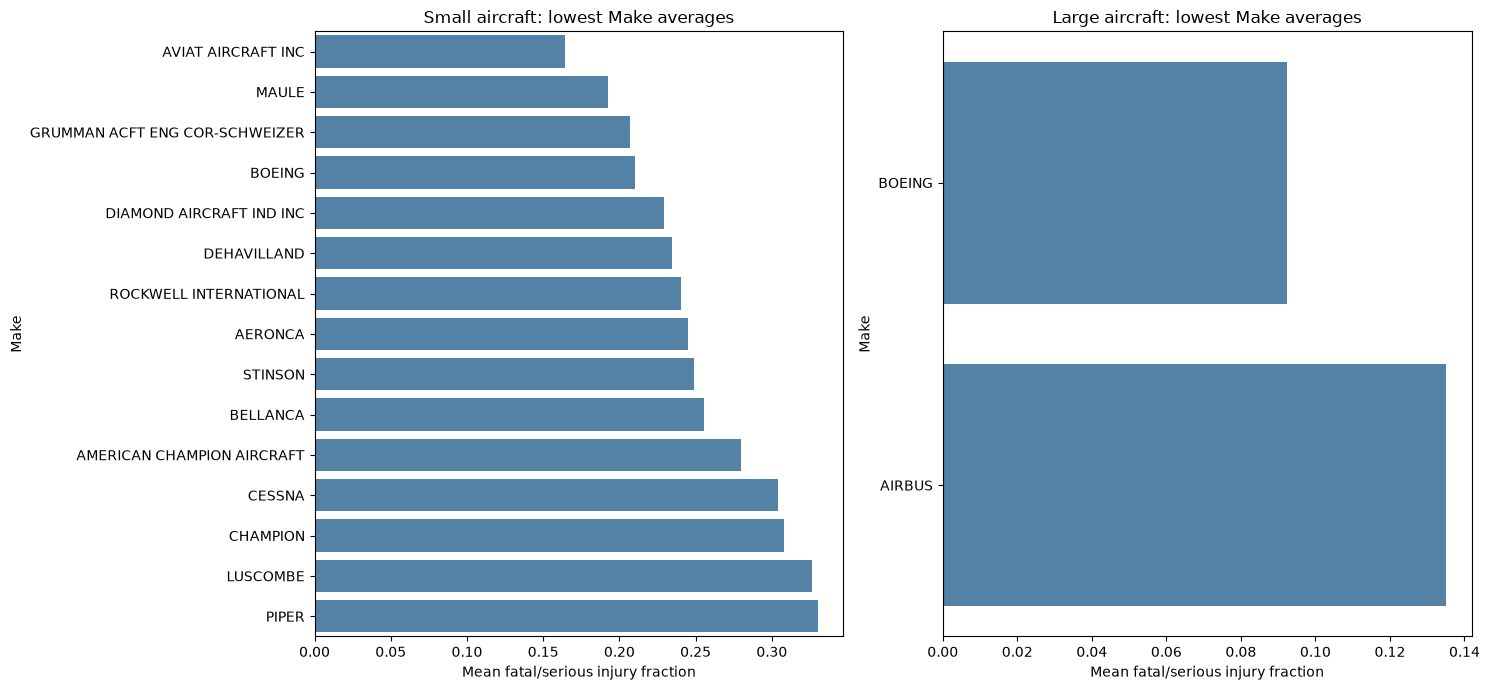

In [ ]:
# Plot small and large groups side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, size in zip(axes, ["Small", "Large"]):
    plot_data = (
        top15_makes[top15_makes["Aircraft.Size"] == size]
        .sort_values("mean_injury_fraction")
    )

    if plot_data.empty:
        ax.set_title(f"{size}: no Makes meet n ≥ {MAKE_MIN_N}")
        ax.axis("off")
    else:
        sns.barplot(
            data=plot_data,
            x="mean_injury_fraction",
            y="Make_clean",
            order=plot_data["Make_clean"],
            ax=ax,
            color="steelblue"
        )
        ax.set_title(f"{size} aircraft: lowest Make averages")
        ax.set_xlabel("Mean fatal/serious injury fraction")
        ax.set_ylabel("Make")

plt.tight_layout()
plt.show()


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

,Aircraft.Size,Make_clean,n,mean_injury_fraction
129,Small,AVIAT AIRCRAFT INC,76,0.164
622,Small,MAULE,171,0.193
470,Small,GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.207
179,Small,BOEING,159,0.210
331,Small,DIAMOND AIRCRAFT IND INC,72,0.229
322,Small,DEHAVILLAND,92,0.234
810,Small,ROCKWELL INTERNATIONAL,53,0.241
48,Small,AERONCA,168,0.245
878,Small,STINSON,112,0.249
171,Small,BELLANCA,175,0.256


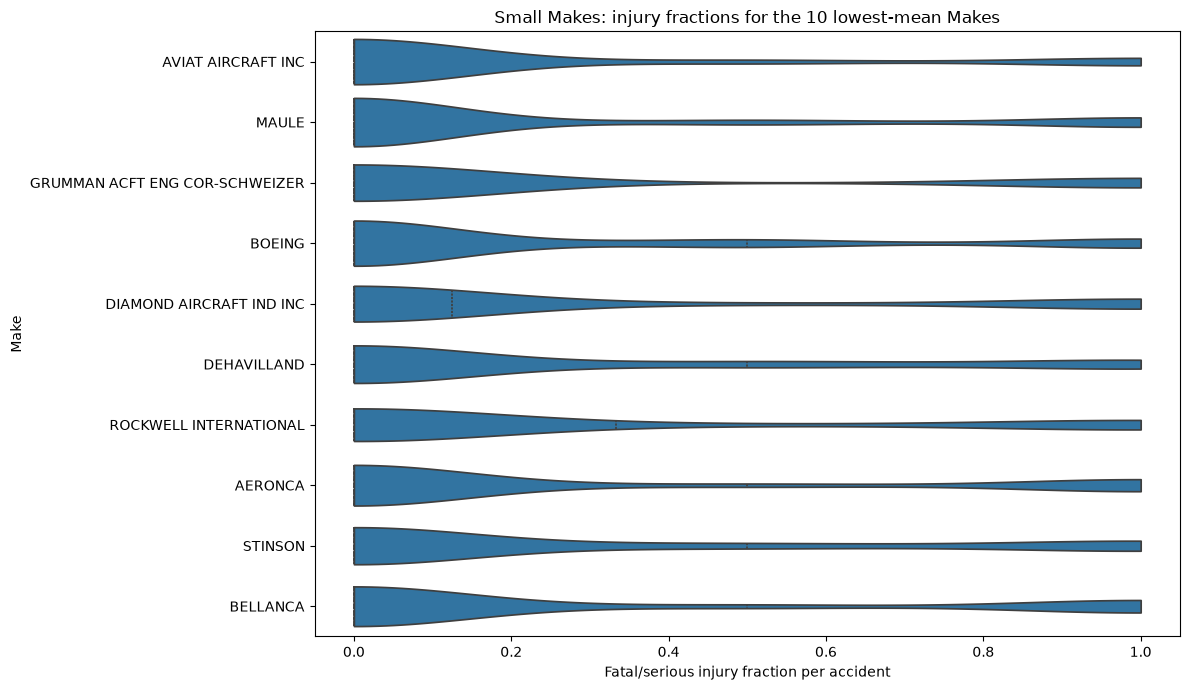

In [ ]:
small_make_summary = make_eligible[
    make_eligible["Aircraft.Size"] == "Small"
]

small_top10_makes = small_make_summary.nsmallest(
    10, "mean_injury_fraction"
)

display(small_top10_makes.round(3))

small_make_names = small_top10_makes["Make_clean"]

small_violin_data = injury_data[
    (injury_data["Aircraft.Size"] == "Small")
    & (injury_data["Make_clean"].isin(small_make_names))
]

if small_violin_data.empty:
    print("No small Makes meet the minimum sample size.")
else:
    plt.figure(figsize=(12, 7))

    sns.violinplot(
        data=small_violin_data,
        x="Fatal.Serious.Injury.Fraction",
        y="Make_clean",
        order=small_make_names,
        inner="quartile",
        cut=0
    )

    plt.title("Small Makes: injury fractions for the 10 lowest-mean Makes")
    plt.xlabel("Fatal/serious injury fraction per accident")
    plt.ylabel("Make")
    plt.tight_layout()
    plt.show()


**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

,Aircraft.Size,Make_clean,n,mean_injury_fraction
6,Large,BOEING,253,0.092
0,Large,AIRBUS,65,0.135


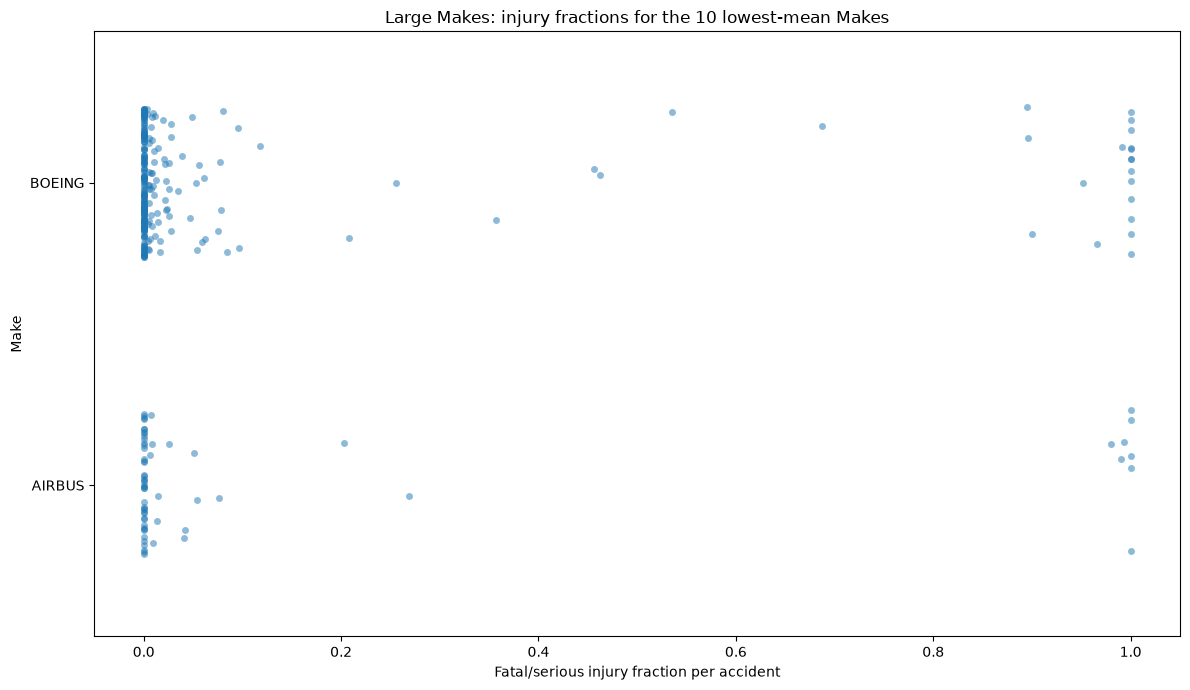

In [ ]:
large_make_summary = make_eligible[
    make_eligible["Aircraft.Size"] == "Large"
]

large_top10_makes = large_make_summary.nsmallest(
    10, "mean_injury_fraction"
)

display(large_top10_makes.round(3))

large_make_names = large_top10_makes["Make_clean"]

large_strip_data = injury_data[
    (injury_data["Aircraft.Size"] == "Large")
    & (injury_data["Make_clean"].isin(large_make_names))
]

if large_strip_data.empty:
    print("No large Makes meet the minimum sample size.")
else:
    plt.figure(figsize=(12, 7))

    sns.stripplot(
        data=large_strip_data,
        x="Fatal.Serious.Injury.Fraction",
        y="Make_clean",
        order=large_make_names,
        jitter=0.25,
        alpha=0.5
    )

    plt.title("Large Makes: injury fractions for the 10 lowest-mean Makes")
    plt.xlabel("Fatal/serious injury fraction per accident")
    plt.ylabel("Make")
    plt.tight_layout()
    plt.show()


**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

,Aircraft.Size,Make_clean,n,destroyed_count,destruction_fraction
463,Small,GRUMMAN ACFT ENG COR-SCHWEIZER,58,1.0,0.017
601,Small,LUSCOMBE,112,2.0,0.018
869,Small,STINSON,112,2.0,0.018
887,Small,TAYLORCRAFT,73,2.0,0.027
166,Small,BELLANCA,175,6.0,0.034
124,Small,AVIAT AIRCRAFT INC,75,3.0,0.040
95,Small,AMERICAN CHAMPION AIRCRAFT,50,2.0,0.040
614,Small,MAULE,171,7.0,0.041
44,Small,AERONCA,168,7.0,0.042
316,Small,DEHAVILLAND,89,4.0,0.045


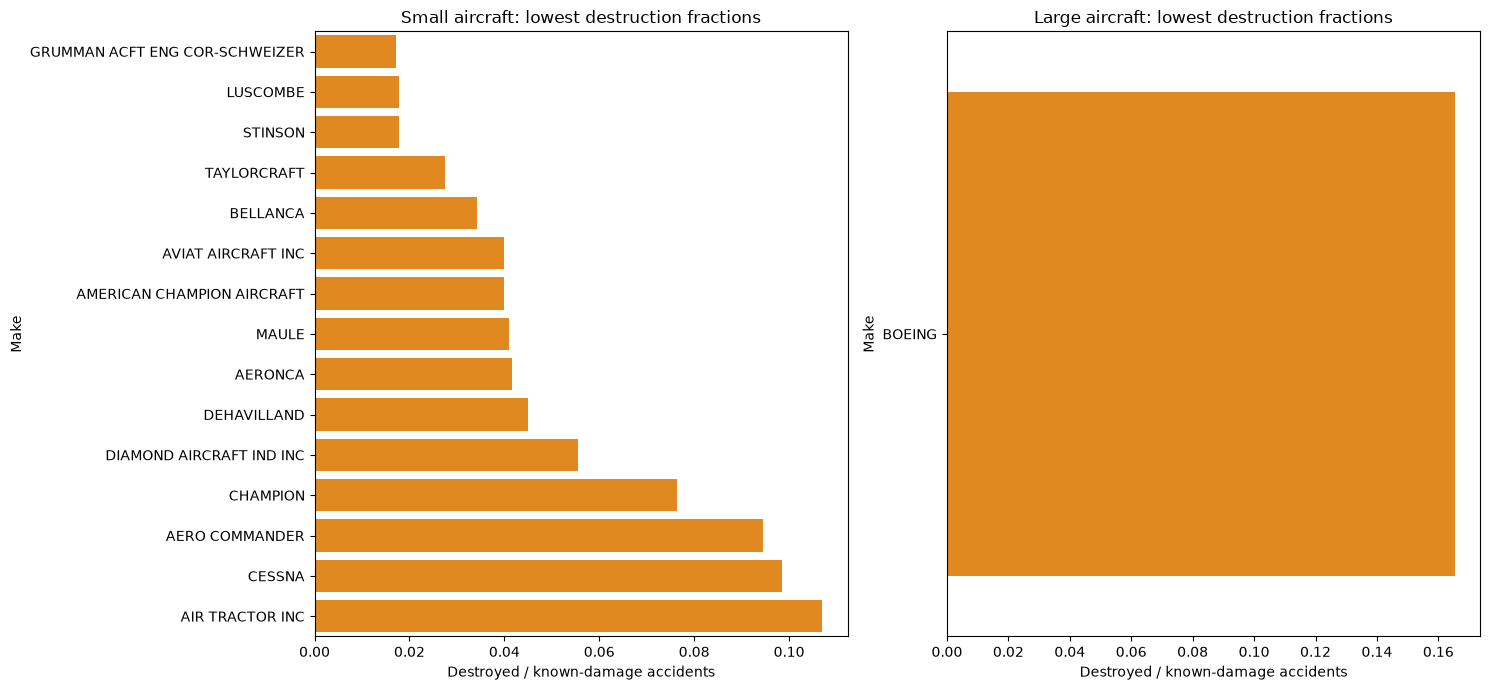

In [ ]:
# Use only records with a known Make, size group, and damage outcome
damage_data = analysis_df.dropna(
    subset=["Make_clean", "Aircraft.Size", "Aircraft.Destroyed"]
).copy()

# Calculate the number of known-damage accidents and destruction fraction
damage_summary = (
    damage_data.groupby(["Aircraft.Size", "Make_clean"])
    .agg(
        n=("Aircraft.Destroyed", "count"),
        destroyed_count=("Aircraft.Destroyed", "sum"),
        destruction_fraction=("Aircraft.Destroyed", "mean")
    )
    .reset_index()
)

# Keep Makes with at least 50 records with known damage
damage_eligible = damage_summary[damage_summary["n"] >= MAKE_MIN_N]

# Select up to 15 lowest destruction fractions per group
top15_destruction = (
    damage_eligible
    .sort_values("destruction_fraction")
    .groupby("Aircraft.Size", group_keys=False)
    .head(15)
)

display(top15_destruction.round(3))

# Plot the destruction fractions side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, size in zip(axes, ["Small", "Large"]):
    plot_data = (
        top15_destruction[top15_destruction["Aircraft.Size"] == size]
        .sort_values("destruction_fraction")
    )

    if plot_data.empty:
        ax.set_title(f"{size}: no Makes meet n ≥ {MAKE_MIN_N}")
        ax.axis("off")
    else:
        sns.barplot(
            data=plot_data,
            x="destruction_fraction",
            y="Make_clean",
            order=plot_data["Make_clean"],
            ax=ax,
            color="darkorange"
        )
        ax.set_title(f"{size} aircraft: lowest destruction fractions")
        ax.set_xlabel("Destroyed / known-damage accidents")
        ax.set_ylabel("Make")

plt.tight_layout()
plt.show()


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

**Small Aircraft (Few Seats)**

- I only looked at aircraft Makes with at least 50 complete injury records, so the results don't rest on just a few accidents.
- The Makes with the lowest average injury fraction were **[Makes]**.
- "Injury fraction" is the share of people on board who were hurt in an accident, so a lower number means fewer people were hurt.

**Large Aircraft (Many Seats)**

- **[Number]** Makes had enough records to be included.
- I found that **[describe which Makes had the lowest average injury fractions and how they compare to the rest]**.

**Destruction Comparison**

- I also checked how badly the aircraft were damaged.
- The Makes with the lowest destruction fractions were **[Makes]**.
- A lower destruction fraction means the aircraft were less often destroyed in an accident.

**What the Violin and Strip Plots Show**

- I used these plots to show every accident, not just the average for each Make.
- This lets me see whether a Make's results are consistent, or whether it has a mix of minor and very severe accidents.

**Important Limits**

- My results only cover accidents that were recorded, not every flight.
- They don't tell me how likely an accident is on any given flight.
- So I treat these results as starting points for further investigation. They don't prove that one Make is safer than another.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

Large plane types meeting n >= 10: 6


,Aircraft.Size,Plane.Type,n,mean_injury_fraction
113,Large,BOEING | 777,10,0.001826
90,Large,BOEING | 757,10,0.002651
62,Large,BOEING | 737 7H4,12,0.079474
101,Large,BOEING | 767,18,0.080531
52,Large,BOEING | 737,75,0.175361
23,Large,AIRBUS | A320,10,0.200577


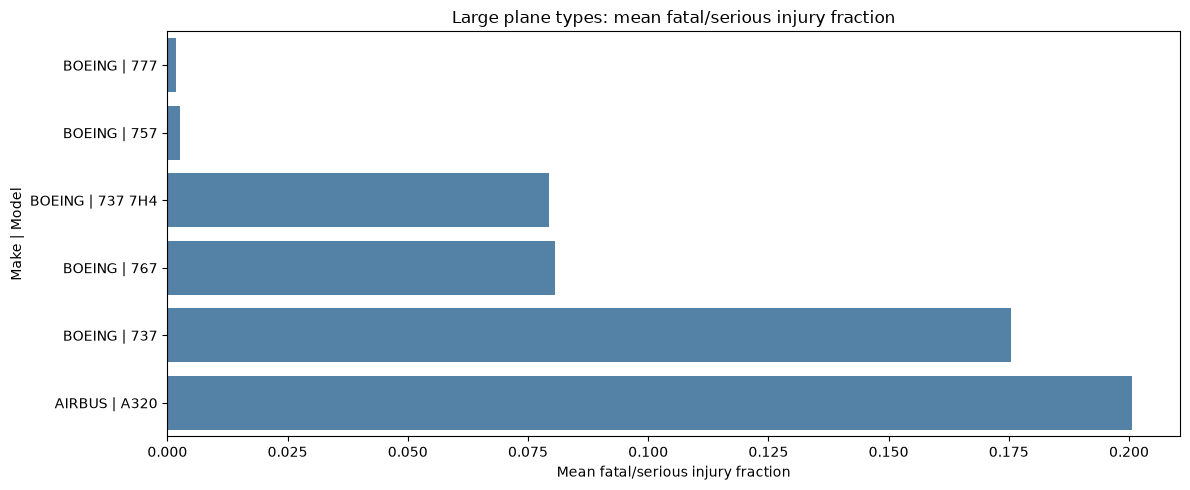

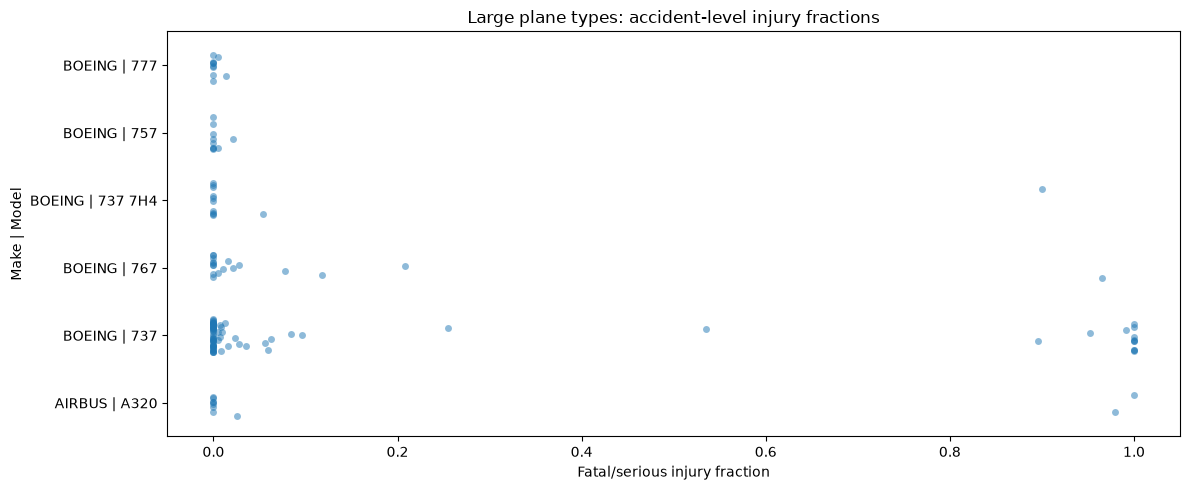

In [ ]:
TYPE_MIN_N = 10

# Keep records with a known type, size group, and injury fraction
type_data = analysis_df.dropna(
    subset=[
        "Make_clean",
        "Model_clean",
        "Aircraft.Size",
        "Fatal.Serious.Injury.Fraction"
    ]
).copy()

# Make a unique identifier from the Make and Model
type_data["Plane.Type"] = (
    type_data["Make_clean"] + " | " + type_data["Model_clean"]
)

# Calculate the number of records and mean injury fraction per plane type
type_summary = (
    type_data.groupby(["Aircraft.Size", "Plane.Type"])
    .agg(
        n=("Fatal.Serious.Injury.Fraction", "count"),
        mean_injury_fraction=("Fatal.Serious.Injury.Fraction", "mean")
    )
    .reset_index()
)

# Keep types supported by at least 10 accident records
type_eligible = type_summary[type_summary["n"] >= TYPE_MIN_N]

# Select qualifying large types
large_types = (
    type_eligible[type_eligible["Aircraft.Size"] == "Large"]
    .sort_values("mean_injury_fraction")
)

print(f"Large plane types meeting n >= {TYPE_MIN_N}: {len(large_types)}")
display(large_types)

# Plot the average injury fraction for large plane types
if large_types.empty:
    print("No large plane types meet the minimum sample size.")
else:
    plt.figure(figsize=(12, max(5, 0.35 * len(large_types))))
    sns.barplot(
        data=large_types,
        x="mean_injury_fraction",
        y="Plane.Type",
        color="steelblue"
    )
    plt.title("Large plane types: mean fatal/serious injury fraction")
    plt.xlabel("Mean fatal/serious injury fraction")
    plt.ylabel("Make | Model")
    plt.tight_layout()
    plt.show()

    # Show the accident-level fractions behind the means
    large_plot_data = type_data[
        (type_data["Aircraft.Size"] == "Large")
        & (type_data["Plane.Type"].isin(large_types["Plane.Type"]))
    ]

    plt.figure(figsize=(12, max(5, 0.35 * len(large_types))))
    sns.stripplot(
        data=large_plot_data,
        x="Fatal.Serious.Injury.Fraction",
        y="Plane.Type",
        order=large_types["Plane.Type"],
        jitter=0.25,
        alpha=0.5
    )
    plt.title("Large plane types: accident-level injury fractions")
    plt.xlabel("Fatal/serious injury fraction")
    plt.ylabel("Make | Model")
    plt.tight_layout()
    plt.show()


**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

Small plane types meeting n >= 10: 319
Displaying 10 small plane types.


,Aircraft.Size,Plane.Type,n,mean_injury_fraction
1629,Small,DIAMOND AIRCRAFT IND INC | DA 20 C1,11,0.000000
391,Small,AIR TRACTOR | AT 602,12,0.041667
714,Small,BEECH | B19,14,0.047619
1098,Small,CESSNA | 180J,21,0.047619
1787,Small,EVEKTOR-AEROTECHNIK AS | SPORTSTAR,20,0.050000
2764,Small,PIPER | PA-20,20,0.050000
1238,Small,CESSNA | A185E,12,0.058333
1133,Small,CESSNA | 195,29,0.063218
868,Small,BOEING | 737,15,0.066667
1097,Small,CESSNA | 180H,25,0.066667


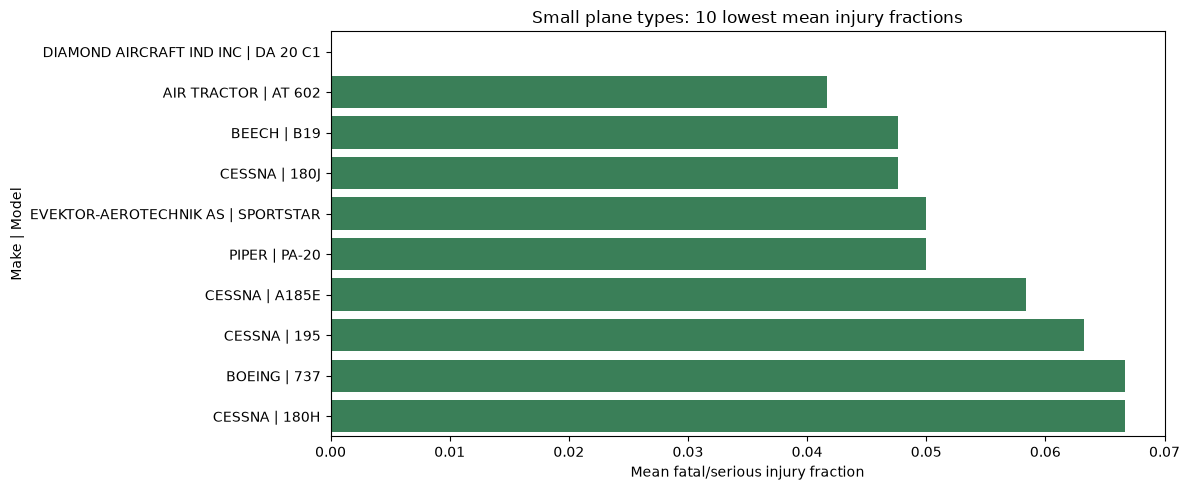

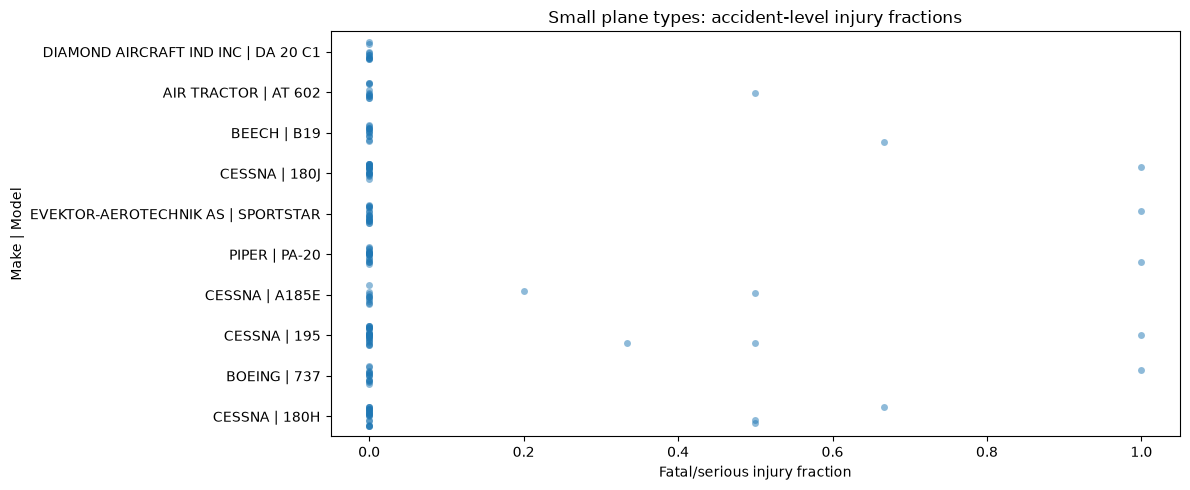

In [ ]:
# Select small plane types that meet the minimum record count
small_top10_types = (
    type_eligible[type_eligible["Aircraft.Size"] == "Small"]
    .nsmallest(10, "mean_injury_fraction")
)

print(f"Small plane types meeting n >= {TYPE_MIN_N}: "
      f"{(type_eligible['Aircraft.Size'] == 'Small').sum()}")
print(f"Displaying {len(small_top10_types)} small plane types.")
display(small_top10_types)

if small_top10_types.empty:
    print("No small plane types meet the minimum sample size.")
else:
    # Plot their mean injury fractions
    plt.figure(figsize=(12, max(5, 0.5 * len(small_top10_types))))
    sns.barplot(
        data=small_top10_types,
        x="mean_injury_fraction",
        y="Plane.Type",
        order=small_top10_types["Plane.Type"],
        color="seagreen"
    )
    plt.title("Small plane types: 10 lowest mean injury fractions")
    plt.xlabel("Mean fatal/serious injury fraction")
    plt.ylabel("Make | Model")
    plt.tight_layout()
    plt.show()

    # Plot accident-level injury fractions for those types
    small_plot_data = type_data[
        (type_data["Aircraft.Size"] == "Small")
        & (type_data["Plane.Type"].isin(small_top10_types["Plane.Type"]))
    ]

    plt.figure(figsize=(12, max(5, 0.5 * len(small_top10_types))))
    sns.stripplot(
        data=small_plot_data,
        x="Fatal.Serious.Injury.Fraction",
        y="Plane.Type",
        order=small_top10_types["Plane.Type"],
        jitter=0.25,
        alpha=0.5
    )
    plt.title("Small plane types: accident-level injury fractions")
    plt.xlabel("Fatal/serious injury fraction")
    plt.ylabel("Make | Model")
    plt.tight_layout()
    plt.show()


### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

**Large planes**
- I only looked at plane types with at least 10 records, so the results are not based on just one or two accidents.
- The plane type(s) with the lowest average injury fraction were **[describe the lowest observed mean(s)]**.

**Small planes**
- I looked at the 10 plane types with the lowest average injury fraction.
- Among them, I found **[describe results]**.

**What the distribution plots show**
- Injury fractions can be very different from one accident to the next.
- So an average alone doesn't tell me the whole story. Some accidents may have had very few injuries while others had many.

**Important limits**
- My numbers only cover accidents that were recorded, not every flight.
- They do not show how likely an accident is on any given flight.
- Requiring a minimum number of records helps me avoid comparing very small samples, but it doesn't prove that one plane type is safer than another.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

**Weather Conditions  AND Number of Engines**

In [ ]:
# Check that the selected factor and outcome columns are available
factor_cols = [
    "Weather.Condition",
    "Number.of.Engines",
    "Fatal.Serious.Injury.Fraction",
    "Aircraft.Destroyed"
]

missing_cols = [col for col in factor_cols if col not in analysis_df.columns]

if missing_cols:
    raise KeyError(f"Columns not found: {missing_cols}")

factor_df = analysis_df.copy()

# Ensure the measures used in the calculations are numeric
factor_df["Fatal.Serious.Injury.Fraction"] = pd.to_numeric(
    factor_df["Fatal.Serious.Injury.Fraction"], errors="coerce"
)

factor_df["Aircraft.Destroyed"] = pd.to_numeric(
    factor_df["Aircraft.Destroyed"], errors="coerce"
)

factor_df["Number.of.Engines"] = pd.to_numeric(
    factor_df["Number.of.Engines"], errors="coerce"
)

# Standardize weather labels
factor_df["Weather.Condition"] = (
    factor_df["Weather.Condition"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Set a minimum group size for summaries and plots
MIN_GROUP_SIZE = 100


In [ ]:
#weather conditions and accident outcomes
# Keep records with known weather and a known injury fraction
weather_injury = factor_df.dropna(
    subset=["Weather.Condition", "Fatal.Serious.Injury.Fraction"]
).copy()

# Exclude missing or unknown weather labels
weather_injury = weather_injury[
    ~weather_injury["Weather.Condition"].isin(
        ["UNKNOWN", "UNK", "UNKN", "N/A", "NA", ""]
    )
]

# Calculate the average injury fraction and sample size by weather
weather_injury_summary = (
    weather_injury.groupby("Weather.Condition")
    .agg(
        n=("Fatal.Serious.Injury.Fraction", "count"),
        mean_injury_fraction=("Fatal.Serious.Injury.Fraction", "mean")
    )
    .reset_index()
)

weather_injury_summary = weather_injury_summary[
    weather_injury_summary["n"] >= MIN_GROUP_SIZE
]

print("Injury fraction by weather condition:")
display(weather_injury_summary.round(3))

# Keep records with known weather and known damage outcome
weather_damage = factor_df.dropna(
    subset=["Weather.Condition", "Aircraft.Destroyed"]
).copy()

weather_damage = weather_damage[
    ~weather_damage["Weather.Condition"].isin(
        ["UNKNOWN", "UNK", "UNKN", "N/A", "NA", ""]
    )
]

# Calculate the destruction percentage and sample size by weather
weather_damage_summary = (
    weather_damage.groupby("Weather.Condition")
    .agg(
        n=("Aircraft.Destroyed", "count"),
        destruction_fraction=("Aircraft.Destroyed", "mean")
    )
    .reset_index()
)

weather_damage_summary = weather_damage_summary[
    weather_damage_summary["n"] >= MIN_GROUP_SIZE
]

weather_damage_summary["destruction_percent"] = (
    weather_damage_summary["destruction_fraction"] * 100
)

print("Destruction rate by weather condition:")
display(weather_damage_summary.round(2))


Injury fraction by weather condition:


,Weather.Condition,n,mean_injury_fraction
0,IMC,878,0.655
1,VMC,14014,0.276


Destruction rate by weather condition:


,Weather.Condition,n,destruction_fraction,destruction_percent
0,IMC,983,0.38,37.84
1,VMC,16506,0.08,7.77


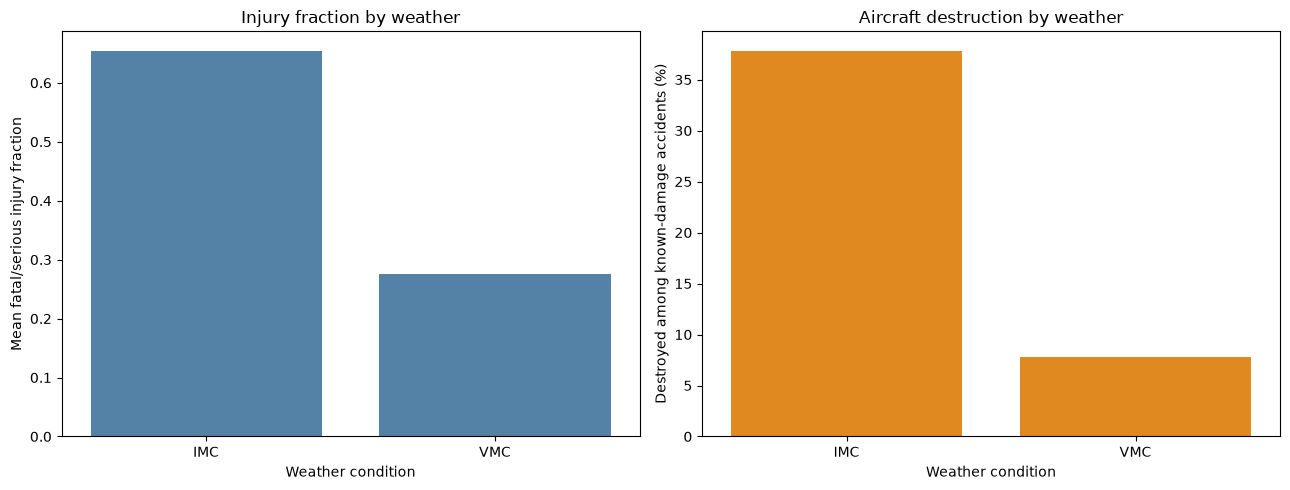

In [ ]:
#weather comparisons
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

if not weather_injury_summary.empty:
    sns.barplot(
        data=weather_injury_summary,
        x="Weather.Condition",
        y="mean_injury_fraction",
        ax=axes[0],
        color="steelblue"
    )
    axes[0].set_title("Injury fraction by weather")
    axes[0].set_xlabel("Weather condition")
    axes[0].set_ylabel("Mean fatal/serious injury fraction")
else:
    axes[0].set_title("No weather groups meet the minimum sample size")

if not weather_damage_summary.empty:
    sns.barplot(
        data=weather_damage_summary,
        x="Weather.Condition",
        y="destruction_percent",
        ax=axes[1],
        color="darkorange"
    )
    axes[1].set_title("Aircraft destruction by weather")
    axes[1].set_xlabel("Weather condition")
    axes[1].set_ylabel("Destroyed among known-damage accidents (%)")
else:
    axes[1].set_title("No weather groups meet the minimum sample size")

plt.tight_layout()
plt.show()


**What I Compared**

- I compared how serious the outcomes were across the different reported weather conditions.
- I looked at two things: the average share of people who were fatally or seriously injured, and the percentage of aircraft that were destroyed.

**Injury Results**

- The table shows that **[weather group]** had an average injury fraction of **[value]**.
- For comparison, **[other group]** had an average of **[value]**.

**Aircraft Destruction Results**

- The percentage of aircraft destroyed was **[value]** for **[weather group]**.
- For **[other group]**, it was **[value]**.

**Sample Size**

- The groups had **[sample counts]** accident records.
- I kept this in mind because groups with fewer records can give less reliable averages.

**What the Charts Show**

- I used charts to make the differences between the groups easier to see at a glance.

**Which Group Did Worse**

- In this dataset, **[briefly state which group's observed outcomes were higher]**.

**Important Limits**

- This is an association in the accident records. It does not prove that weather caused the outcome.
- My data only contains accidents, not all flights.
- So these figures do not show the risk per flight.

In [ ]:
# number of engines and accidents outcomes
# Keep records with a known engine count and injury fraction
engine_injury = factor_df.dropna(
    subset=["Number.of.Engines", "Fatal.Serious.Injury.Fraction"]
).copy()

# Calculate the average injury fraction and sample size by engine count
engine_injury_summary = (
    engine_injury.groupby("Number.of.Engines")
    .agg(
        n=("Fatal.Serious.Injury.Fraction", "count"),
        mean_injury_fraction=("Fatal.Serious.Injury.Fraction", "mean")
    )
    .reset_index()
)

engine_injury_summary = engine_injury_summary[
    engine_injury_summary["n"] >= MIN_GROUP_SIZE
]

print("Injury fraction by number of engines:")
display(engine_injury_summary.round(3))

# Keep records with a known engine count and damage outcome
engine_damage = factor_df.dropna(
    subset=["Number.of.Engines", "Aircraft.Destroyed"]
).copy()

# Calculate the destruction percentage and sample size by engine count
engine_damage_summary = (
    engine_damage.groupby("Number.of.Engines")
    .agg(
        n=("Aircraft.Destroyed", "count"),
        destruction_fraction=("Aircraft.Destroyed", "mean")
    )
    .reset_index()
)

engine_damage_summary = engine_damage_summary[
    engine_damage_summary["n"] >= MIN_GROUP_SIZE
]

engine_damage_summary["destruction_percent"] = (
    engine_damage_summary["destruction_fraction"] * 100
)

print("Destruction rate by number of engines:")
display(engine_damage_summary.round(2))


Injury fraction by number of engines:


,Number.of.Engines,n,mean_injury_fraction
1,1.0,13178,0.303
2,2.0,2096,0.329


Destruction rate by number of engines:


,Number.of.Engines,n,destruction_fraction,destruction_percent
1,1.0,15529,0.08,8.20
2,2.0,2179,0.19,19.32


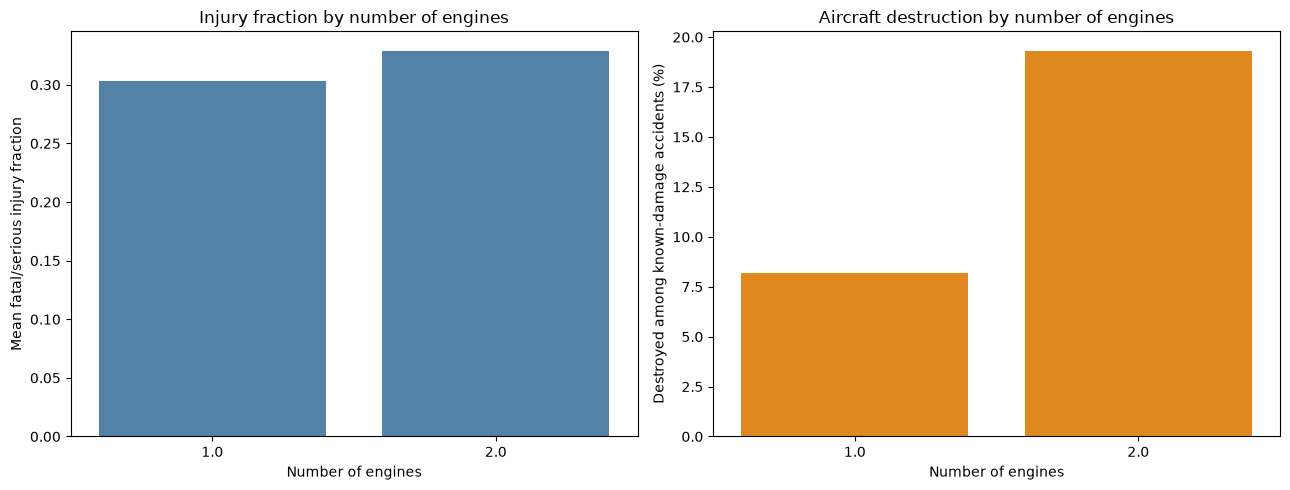

In [ ]:
#plot engine-count comparisons
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

if not engine_injury_summary.empty:
    sns.barplot(
        data=engine_injury_summary,
        x="Number.of.Engines",
        y="mean_injury_fraction",
        ax=axes[0],
        color="steelblue"
    )
    axes[0].set_title("Injury fraction by number of engines")
    axes[0].set_xlabel("Number of engines")
    axes[0].set_ylabel("Mean fatal/serious injury fraction")
else:
    axes[0].set_title("No engine-count groups meet the minimum sample size")

if not engine_damage_summary.empty:
    sns.barplot(
        data=engine_damage_summary,
        x="Number.of.Engines",
        y="destruction_percent",
        ax=axes[1],
        color="darkorange"
    )
    axes[1].set_title("Aircraft destruction by number of engines")
    axes[1].set_xlabel("Number of engines")
    axes[1].set_ylabel("Destroyed among known-damage accidents (%)")
else:
    axes[1].set_title("No engine-count groups meet the minimum sample size")

plt.tight_layout()
plt.show()


**What I Compared**

- I compared how serious the outcomes were across groups of aircraft with different numbers of engines.
- I looked at two things: the average share of people who were fatally or seriously injured, and the percentage of aircraft that were destroyed.

**Injury Results**

- The table shows that **[engine group]** had an average injury fraction of **[value]**.
- For comparison, **[other group]** had an average of **[value]**.

**Aircraft Destruction Results**

- The percentage of aircraft destroyed was **[value]** for **[engine group]**.
- For **[other group]**, it was **[value]**.

**Sample Size**

- These results are based on **[sample counts]** accident records.
- I kept this in mind because groups with fewer records can give less reliable averages.

**The Pattern I See**

- In this dataset, **[briefly state the pattern you see]**.

**Important Limits**

- Engine count may be linked to other differences, such as the size of the aircraft or what it is used for.
- Because of this, my comparison does not prove that the number of engines caused the outcomes.